## UC-08 : Analyse des données et visualisation

In [1]:

import sys
from pathlib import Path

print("Python :", sys.executable)
print("Dossier actuel :", Path.cwd())
print("Système :", sys.platform)


Python : /usr/local/bin/python3.13
Dossier actuel : /workspace
Système : linux


In [2]:

import zipfile
from pathlib import Path

chemin_zip = Path("/workspace/retail_project (1).zip")

print("ZIP trouvé :", chemin_zip.exists())

with zipfile.ZipFile(chemin_zip, "r") as fichier:
    noms = fichier.namelist()

    print("Nombre de fichiers dans le ZIP :", len(noms))

    print("\nPremiers éléments du ZIP :")
    for nom in noms[:20]:
        print(nom)

print("\nContenu actuel de Projet 4 :")
for element in Path("/workspace/Projet 4").iterdir():
    print(element.name)


ZIP trouvé : True
Nombre de fichiers dans le ZIP : 73

Premiers éléments du ZIP :
retail_project/
retail_project/data/
retail_project/data/customer/
retail_project/data/customer/customer.dat
retail_project/data/customer_address/
retail_project/data/customer_address/customer_address.dat
retail_project/data/customer_demographics/
retail_project/data/customer_demographics/customer_demographics.dat
retail_project/data/date_dim/
retail_project/data/date_dim/date_dim.dat
retail_project/data/household_demographics/
retail_project/data/household_demographics/household_demographics.dat
retail_project/data/income_band/
retail_project/data/income_band/income_band.dat
retail_project/data/inventory/
retail_project/data/inventory/inventory.dat
retail_project/data/item/
retail_project/data/item/item.dat
retail_project/data/item_marketprices/
retail_project/data/item_marketprices/item_marketprices.dat

Contenu actuel de Projet 4 :
.ipynb_checkpoints
api
models
Phase1.ipynb
Phase2.ipynb
Phase3.ipynb
Ph

In [3]:

from pathlib import Path

base = Path("/workspace/Projet 4/retail_project")

fichiers = [
    "data/date_dim/date_dim.dat",
    "data/item/item.dat",
    "data/store_sales/store_sales.dat",
    "data/web_sales/web_sales.dat"
]

for fichier in fichiers:
    chemin = base / fichier
    print(fichier, ":", "Présent" if chemin.is_file() else "Absent")

for dossier in ["data", "data_refresh"]:
    chemin = base / dossier

    if chemin.is_dir():
        tables = [p for p in chemin.iterdir() if p.is_dir()]
        print(dossier, ":", len(tables), "tables")
    else:
        print(dossier, ": absent")


data/date_dim/date_dim.dat : Présent
data/item/item.dat : Présent
data/store_sales/store_sales.dat : Présent
data/web_sales/web_sales.dat : Présent
data : 23 tables
data_refresh : 11 tables


## Étape 1 : Sélectionner les données

### 1.2 Vérifier les fichiers disponibles

In [4]:

from pathlib import Path

base = Path("/workspace/Projet 4/retail_project/data")
tables = ["store_sales", "web_sales", "item", "date_dim"]
for table in tables:
    fichier = base / table / f"{table}.dat"

    print(
        table,
        ":",
        "Présent" if fichier.is_file() else "Absent"
    )


store_sales : Présent
web_sales : Présent
item : Présent
date_dim : Présent


### 1.3 – Charger les données dans Spark

In [7]:

from pyspark.sql import SparkSession
from pyspark.sql import functions as F
spark = (SparkSession.builder.appName("TP4-Retail-Intelligence").master("local[*]").getOrCreate())

dataframes = {}
for table in tables:
    chemin = str(base / table / f"{table}.dat")

    dataframes[table] = (spark.read.option("sep", "|")
        .option("header", "false")
        .option("inferSchema", "true")
        .csv(chemin))

    print(table,":",len(dataframes[table].columns),"colonnes")
for nom, df in dataframes.items():
    print("\nTable :", nom)
    print("Nombre de colonnes :", len(df.columns))

    df.printSchema()

store_sales : 23 colonnes


web_sales : 34 colonnes
item : 22 colonnes
date_dim : 28 colonnes

Table : store_sales
Nombre de colonnes : 23
root
 |-- _c0: integer (nullable = true)
 |-- _c1: integer (nullable = true)
 |-- _c2: integer (nullable = true)
 |-- _c3: integer (nullable = true)
 |-- _c4: integer (nullable = true)
 |-- _c5: integer (nullable = true)
 |-- _c6: integer (nullable = true)
 |-- _c7: integer (nullable = true)
 |-- _c8: integer (nullable = true)
 |-- _c9: integer (nullable = true)
 |-- _c10: integer (nullable = true)
 |-- _c11: double (nullable = true)
 |-- _c12: double (nullable = true)
 |-- _c13: double (nullable = true)
 |-- _c14: double (nullable = true)
 |-- _c15: double (nullable = true)
 |-- _c16: double (nullable = true)
 |-- _c17: double (nullable = true)
 |-- _c18: double (nullable = true)
 |-- _c19: double (nullable = true)
 |-- _c20: double (nullable = true)
 |-- _c21: double (nullable = true)
 |-- _c22: double (nullable = true)


Table : web_sales
Nombre de colonnes : 34
root
 |-- _

### 1.4 – Vérifier les premières lignes des données

In [8]:
for nom, df in dataframes.items():
    print("Table :", nom)
    display(df.limit(5).toPandas())


Table : store_sales


/usr/local/lib/python3.13/site-packages/pyspark/sql/pandas/conversion.py:324: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


,_c0,_c1,_c2,_c3,_c4,_c5,_c6,_c7,_c8,_c9,...,_c13,_c14,_c15,_c16,_c17,_c18,_c19,_c20,_c21,_c22
0,36890,71480,10001,44404,493944,2898,44093,10,294,0,...,23.08,238.70,715.48,558.00,954.18,21.46,0.00,715.48,736.94,157.48
1,36890,71480,10000,44404,493944,2898,44093,10,279,0,...,83.34,3535.92,4500.36,5357.34,8036.28,225.02,0.00,4500.36,4725.38,-856.98
2,36890,71480,15556,44404,493944,2898,44093,10,114,0,...,83.24,442.65,3246.36,3100.11,3689.01,184.07,616.81,2629.55,2813.62,-470.56
3,36890,45392,4597,89832,1774847,6266,16285,4,285,1,...,133.40,54.40,2668.00,1487.60,2722.40,133.40,0.00,2668.00,2801.40,1180.40
4,36890,45392,3258,89832,1774847,6266,16285,4,230,1,...,11.85,197.60,900.60,747.08,1098.20,18.01,0.00,900.60,918.61,153.52


Table : web_sales


/usr/local/lib/python3.13/site-packages/pyspark/sql/pandas/conversion.py:324: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
26/11/21 12:14:27 WARN SparkStringUtils: Truncated the string representation of a plan since it was too large. This behavior can be adjusted by setting 'spark.sql.debug.maxToStringFields'.


,_c0,_c1,_c2,_c3,_c4,_c5,_c6,_c7,_c8,_c9,...,_c24,_c25,_c26,_c27,_c28,_c29,_c30,_c31,_c32,_c33
0,36890,26789,36993,794,85457,380790,2436,42649,29934,1583844,...,3033.66,7553.46,330.84,0.00,1661.76,5513.97,5844.81,7175.73,7506.57,2480.31
1,36890,26789,36953,9897,85457,380790,2436,42649,29934,1583844,...,1208.40,1897.20,31.42,470.58,796.82,1047.42,1078.84,1844.24,1875.66,-160.98
2,36890,26789,36906,3725,85457,380790,2436,42649,29934,1583844,...,4726.26,12950.25,0.00,0.00,129.50,12820.98,12820.98,12950.48,12950.48,8094.72
3,36890,26789,36961,8230,85457,380790,2436,42649,29934,1583844,...,1493.78,1702.78,13.62,0.00,136.22,340.48,354.10,476.70,490.32,-1153.30
4,36890,26789,36976,17454,85457,380790,2436,42649,29934,1583844,...,2239.12,6672.64,8.94,4291.62,2802.51,178.82,187.76,2981.33,2990.27,-2060.30


... (2 outputs left out)

,_c0,_c1,_c2,_c3,_c4,_c5,_c6,_c7,_c8,_c9,...,_c12,_c13,_c14,_c15,_c16,_c17,_c18,_c19,_c20,_c21
0,0,AAAAAAAAAAAAAAAA,2000-01-14,NaN,quickly even dinos beneath the frays must have...,72.29,64.96,3898712,71TS7NSbvH1YbdiQMG6ttBHKAljiNoIRB,1,...,Sports & Outdoors,995,2VOxvrIWwlJQTSk6,small,99Ee1r6uFbZSSClAX3,dodger,Oz,Unknown,18,8m9n5Q7T33DNWidoA6nWlg6ydmpA1SKOoOJLXiLVb
1,1,AAAAAAAAAAAAAAAB,2000-09-23,NaN,quietly quiet hockey players outside the furio...,95.67,30.57,2218494,qNBimHGBu763udH,4,...,Books,69,M0VWtUYYkxy6iEMa2XZOxQSCTxFrOqsXg,petite,dz1S8VrTflBJIq1kC61,tan,Dram,Unknown,91,CPB648WB37uUv5OCqjzYe7rH3T
2,2,AAAAAAAAAAAAAAAC,2000-09-01,NaN,dogged dugouts need to maintain regularly in p...,62.74,47.70,6043423,ma5,3,...,Books,831,SXEWAxq6kTcO8sAwISBAM9,N/A,nF9XEmsyODYrRYXE2P8H,mint,Bunch,Unknown,19,bMcWnXWH4yWhqADKdlZicQXcIhd48e8iROsScTzHAKPFcgh8
3,3,AAAAAAAAAAAAAAAD,2000-12-12,NaN,ideas within the quiet sly asymptotes maintain...,98.67,76.61,7023779,op9d25ZWK4zQ7JNAc,3,...,Books,289,GJG7sd2NX3jWQ75hZnibJ9PpCpdnish8TWzGw2x8jv,petite,DO8ImgmTbjXFBHux,pink,Case,Unknown,99,gqbhNi4JCS7
4,4,AAAAAAAAAAAAAAAE,2000-04-04,NaN,permanent careful notornis engage inside the s...,40.95,82.68,5087894,RYLn4HY3I3kooPCNhwV,2,...,Books,511,x83t3sgzXqyvPSbg8eTcyBXWAYNeak7EvFJVBMP4lB3Q2W...,large,tOrdc4PMUMrwZto1eZdL,blanched,Dram,Unknown,54,WinA


Table : date_dim


/usr/local/lib/python3.13/site-packages/pyspark/sql/pandas/conversion.py:324: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


,_c0,_c1,_c2,_c3,_c4,_c5,_c6,_c7,_c8,_c9,...,_c18,_c19,_c20,_c21,_c22,_c23,_c24,_c25,_c26,_c27
0,0,AAAAAAAAAAAAAAAA,1900-01-01,0,0,0,1900,1,1,1,...,N,2448812,2458802,2472542,2420941,N,N,N,N,N
1,1,AAAAAAAAAAAAAAAB,1900-01-02,0,0,0,1900,2,1,2,...,N,2441612,2427135,2449909,2430434,N,N,N,N,N
2,2,AAAAAAAAAAAAAAAC,1900-01-03,0,0,0,1900,3,1,3,...,N,2436156,2449280,2455660,2433174,N,N,N,N,N
3,3,AAAAAAAAAAAAAAAD,1900-01-04,0,0,0,1900,4,1,4,...,Y,2417967,2415922,2478062,2434335,N,N,N,N,N
4,4,AAAAAAAAAAAAAAAE,1900-01-05,0,0,0,1900,5,1,5,...,Y,2476746,2478037,2449873,2441986,N,N,N,N,N


### 1.5 Comprendre la différence entre calcul et visualisation


#### 1.5.1 Calculer les ventes par magasin

In [13]:
df_ventes_magasin = dataframes["store_sales"].select(
    F.col("_c7").alias("magasin"),
    F.col("_c20").alias("montant_vente"))

ventes_par_magasin = (
    df_ventes_magasin.groupBy("magasin").agg(
        F.sum("montant_vente").alias("total_ventes"))
    .orderBy(F.desc("total_ventes")))
display(ventes_par_magasin.toPandas())


/usr/local/lib/python3.13/site-packages/pyspark/sql/pandas/conversion.py:324: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
                                                                                

,magasin,total_ventes
0,7,98950137.76
1,4,96770105.59
2,9,96748356.68
3,0,96727851.94
4,8,96578622.89
5,3,96063990.59
6,1,95929844.66
7,11,95607843.48
8,6,94751173.08
9,10,94263977.55


#### 1.5.2 – Récupérer le résultat dans Pandas

In [14]:
pdf_ventes = ventes_par_magasin.toPandas()
display(pdf_ventes)


/usr/local/lib/python3.13/site-packages/pyspark/sql/pandas/conversion.py:324: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


,magasin,total_ventes
0,7,98950137.76
1,4,96770105.59
2,9,96748356.68
3,0,96727851.94
4,8,96578622.89
5,3,96063990.59
6,1,95929844.66
7,11,95607843.48
8,6,94751173.08
9,10,94263977.55


### 1.6 – Montant total des ventes par magasin

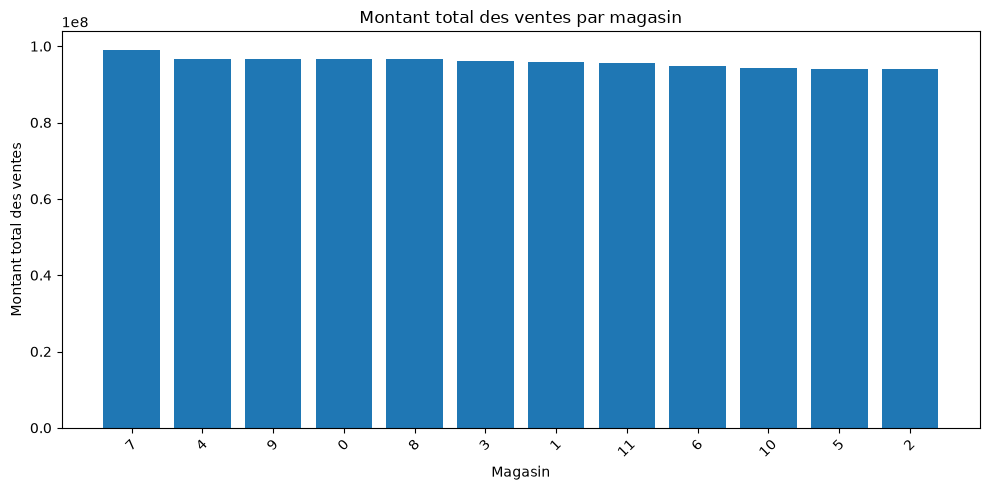

In [16]:

import matplotlib.pyplot as plt
plt.figure(figsize=(10, 5))

plt.bar(pdf_ventes["magasin"].astype(str),pdf_ventes["total_ventes"])
plt.title("Montant total des ventes par magasin")
plt.xlabel("Magasin")
plt.ylabel("Montant total des ventes")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


### 1.7 – Créer une visualisation temporelle

#### 1.7.1 – Regrouper les ventes par mois

In [17]:

from pyspark.sql import functions as F
dates = dataframes["date_dim"].select(F.col("_c0").alias("date_sk"),F.to_date("_c2").alias("date_vente")
)

ventes_dates = dataframes["store_sales"].join(dates,F.col("_c0") == F.col("date_sk"),
    "inner")

ventes_par_mois = (
    ventes_dates.withColumn("mois",F.date_format("date_vente", "yyyy-MM"))
    .groupBy("mois").agg(F.sum("_c20").alias("total_ventes")).orderBy("mois")
)
display(ventes_par_mois.toPandas())


/usr/local/lib/python3.13/site-packages/pyspark/sql/pandas/conversion.py:324: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


,mois,total_ventes
0,2001-01,19279633.40
1,2001-02,17989228.47
2,2001-03,19630651.08
3,2001-04,18915426.86
4,2001-05,19786451.19
5,2001-06,19399244.10
6,2001-07,19985336.68
7,2001-08,19552826.03
8,2001-09,19442330.41
9,2001-10,20078324.18


#### 1.7.2 – Évolution des ventes par mois

/usr/local/lib/python3.13/site-packages/pyspark/sql/pandas/conversion.py:324: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


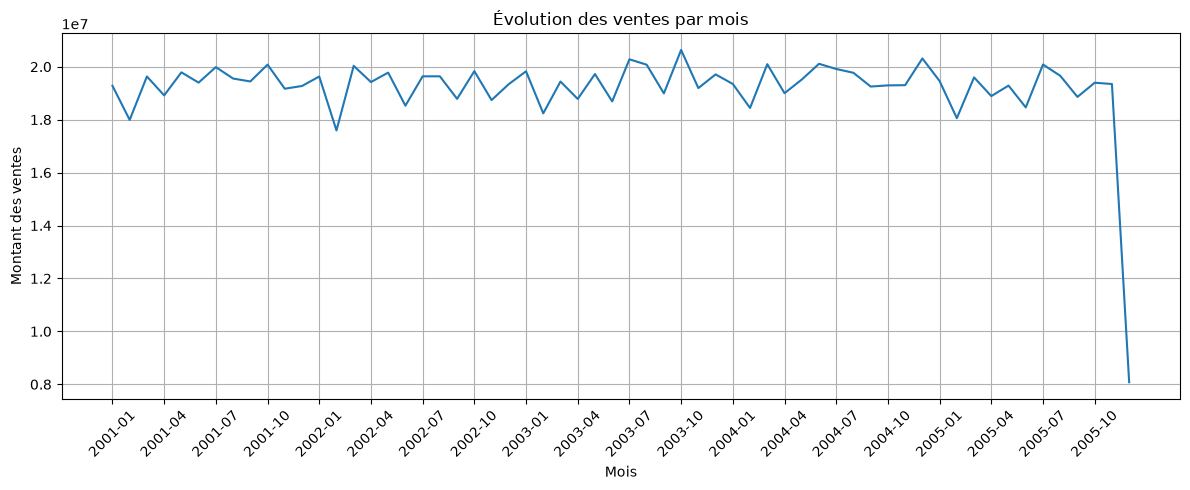

In [22]:
import matplotlib.pyplot as plt
pdf_mois = ventes_par_mois.toPandas()
plt.figure(figsize=(12, 5))
plt.plot(pdf_mois["mois"], pdf_mois["total_ventes"])
plt.title("Évolution des ventes par mois")
plt.xlabel("Mois")
plt.ylabel("Montant des ventes")
plt.xticks(range(0, len(pdf_mois), 3),pdf_mois["mois"][::3],rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()


#### 1.7.3 – Top 10 des produits selon le montant des ventes

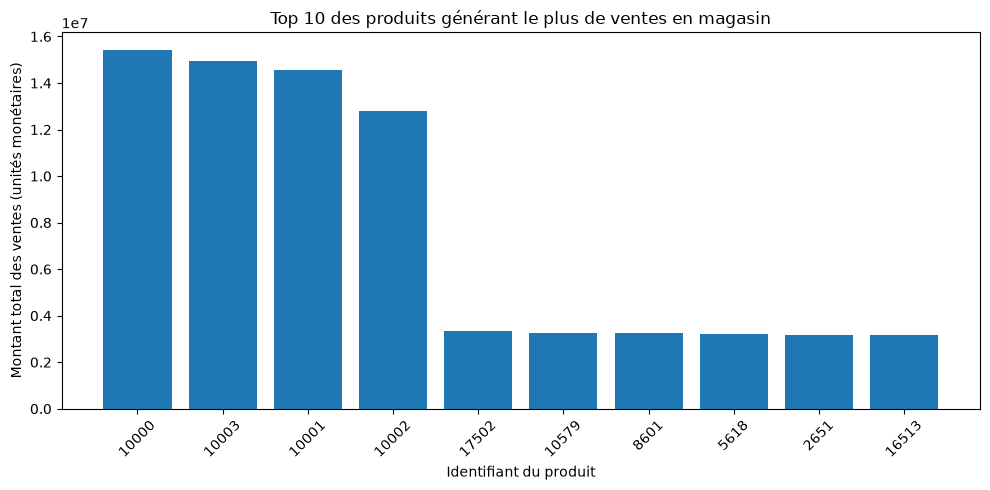

In [28]:

from pyspark.sql import functions as F
import matplotlib.pyplot as plt

produits = dataframes["item"].select(F.col("_c0").alias("item_sk"),
    F.col("_c21").alias("nom_produit"))

ventes_produits = (
    dataframes["store_sales"].groupBy("_c2").agg(F.sum("_c20").alias("total_ventes"))
)

top_produits = (
    ventes_produits.join(produits, ventes_produits["_c2"] == produits["item_sk"])
    .orderBy(F.desc("total_ventes"))
    .limit(10))
plt.figure(figsize=(10, 5))

plt.bar(pdf_produits["_c2"].astype(str),pdf_produits["total_ventes"])
plt.title("Top 10 des produits générant le plus de ventes en magasin")
plt.xlabel("Identifiant du produit")
plt.ylabel("Montant total des ventes (unités monétaires)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


###  2.1 – Sélectionner les données

#### 2.1.1 – Vérifier les données disponibles

In [32]:

from pathlib import Path

# Récupérer 100 lignes du fichier source TPCx-BB
source = Path("/workspace/Projet 4/retail_project/data/store_sales/store_sales.dat")
destination = Path("/workspace/echantillon_store_sales.dat")

with source.open("r", encoding="utf-8") as fichier:
    lignes = [next(fichier) for _ in range(100)]

with destination.open("w", encoding="utf-8") as fichier:
    fichier.writelines(lignes)

print("Fichier créé :", destination)
print("Taille :", destination.stat().st_size, "octets")


Fichier créé : /workspace/echantillon_store_sales.dat
Taille : 13394 octets


#### 2.1.2 – Préparer les données Silver

In [36]:
silver_ventes = dataframes["store_sales"].select(F.col("_c0").alias("date_id"),
    F.col("_c2").alias("produit_id"),F.col("_c7").alias("magasin_id"),
    F.col("_c20").cast("double").alias("montant_vente"))
silver_ventes.show(5)
print("Nombre de lignes :", silver_ventes.count())

silver_ventes.select([F.count(F.when(F.col(c).isNull(), c)).alias(c)
    for c in silver_ventes.columns]).show()
print("Montants négatifs :", silver_ventes.filter(F.col("montant_vente") < 0).count())

silver_ventes.write.mode("overwrite").parquet("/workspace/Projet 4/retail_project/silver/ventes")
print("Données Silver enregistrées")

+-------+----------+----------+-------------+
|date_id|produit_id|magasin_id|montant_vente|
+-------+----------+----------+-------------+
|  36890|     10001|        10|       715.48|
|  36890|     10000|        10|      4500.36|
|  36890|     15556|        10|      2629.55|
|  36890|      4597|         4|       2668.0|
|  36890|      3258|         4|        900.6|
+-------+----------+----------+-------------+
only showing top 5 rows


Nombre de lignes : 667579
+-------+----------+----------+-------------+
|date_id|produit_id|magasin_id|montant_vente|
+-------+----------+----------+-------------+
|      0|         0|         0|            0|
+-------+----------+----------+-------------+

Montants négatifs : 0


26/11/21 14:43:54 WARN MemoryManager: Total allocation exceeds 95.00% (1,020,054,720 bytes) of heap memory
Scaling row group sizes to 95.00% for 8 writers
                                                                                

Données Silver enregistrées


#### 2.1.3 – Préparer les données Gold

In [37]:
gold_ventes = silver_ventes.groupBy("magasin_id").agg(F.round(F.sum("montant_vente"), 2).alias("total_ventes"))
gold_ventes.show()
gold_ventes.write.mode("overwrite").parquet("/workspace/Projet 4/retail_project/gold/indicateurs")
print("Données Gold enregistrées")

+----------+-------------+
|magasin_id| total_ventes|
+----------+-------------+
|         1|9.592984466E7|
|         6|9.475117308E7|
|         3|9.606399059E7|
|         5|9.409727937E7|
|         9|9.674835668E7|
|         4|9.677010559E7|
|         8|9.657862289E7|
|         7|9.895013776E7|
|        10|9.426397755E7|
|        11|9.560784348E7|
|         2|9.404040278E7|
|         0|9.672785194E7|
+----------+-------------+

Données Gold enregistrées


#### 2.2 – Calculer les KP

In [38]:
kpi = silver_ventes.agg(F.round(F.sum("montant_vente"), 2).alias("total_ventes"),
    F.round(F.avg("montant_vente"), 2).alias("moyenne_par_ligne"),
    F.countDistinct("produit_id").alias("nombre_produits"))
kpi.show()

[Stage 110:=======>                                                 (1 + 7) / 8]

+---------------+-----------------+---------------+
|   total_ventes|moyenne_par_ligne|nombre_produits|
+---------------+-----------------+---------------+
|1.15052958637E9|          1723.44|          17820|
+---------------+-----------------+---------------+



#### 2.3 – Statistiques descriptives

In [39]:
silver_ventes.select(F.count("*").alias("nb_ventes"),F.round(F.min("montant_vente"), 2).alias("minimum"),
    F.round(F.max("montant_vente"), 2).alias("maximum"),
    F.round(F.avg("montant_vente"), 2).alias("moyenne")).show()
mediane = silver_ventes.approxQuantile("montant_vente", [0.5], 0.01)
print("Médiane :", mediane[0])

+---------+-------+-------+-------+
|nb_ventes|minimum|maximum|moyenne|
+---------+-------+-------+-------+
|   667579|    0.0|18745.0|1723.44|
+---------+-------+-------+-------+



[Stage 119:>                                                        (0 + 8) / 8]

Médiane : 863.3


#### 2.4 – Analyses métier

In [40]:
print("Ventes par magasin")
gold_ventes.orderBy(F.desc("total_ventes")).show(5)
print("Top 10 des produits")
top_produits = silver_ventes.groupBy("produit_id").agg(F.round(F.sum("montant_vente"), 2).alias("total_ventes")
)
top_produits.orderBy(F.desc("total_ventes")).show(10)

Ventes par magasin


+----------+-------------+
|magasin_id| total_ventes|
+----------+-------------+
|         7|9.895013776E7|
|         4|9.677010559E7|
|         9|9.674835668E7|
|         0|9.672785194E7|
|         8|9.657862289E7|
+----------+-------------+
only showing top 5 rows
Top 10 des produits


[Stage 125:=======>                                                 (1 + 7) / 8]

+----------+-------------+
|produit_id| total_ventes|
+----------+-------------+
|     10000|1.540839355E7|
|     10003| 1.49338701E7|
|     10001|1.457212466E7|
|     10002|1.281743786E7|
|     17502|   3336529.83|
|     10579|   3250367.57|
|      8601|   3238749.92|
|      5618|   3212955.42|
|      2651|   3172287.79|
|     16513|   3162636.37|
+----------+-------------+
only showing top 10 rows
